# ML Practical 4 – K-Means Clustering

**Aim:** Apply K-Means clustering to the Iris dataset, find a suitable number of clusters using the Elbow Method, and visualize clusters.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
url = "https://raw.githubusercontent.com/uiuc-cse/data-fa14/gh-pages/data/iris.csv"
data = pd.read_csv(url)

print("First 5 rows:")
print(data.head())
print("\nDataset Information:")
data.info()
print("\nStatistical Summary:")
print(data.describe())
print("\nMissing Values:")
print(data.isnull().sum())

First 5 rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.0

In [3]:
X = data[["sepal_length", "sepal_width", "petal_length", "petal_width"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_scaled)

print("Cluster Labels:")
print(y_kmeans)

Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


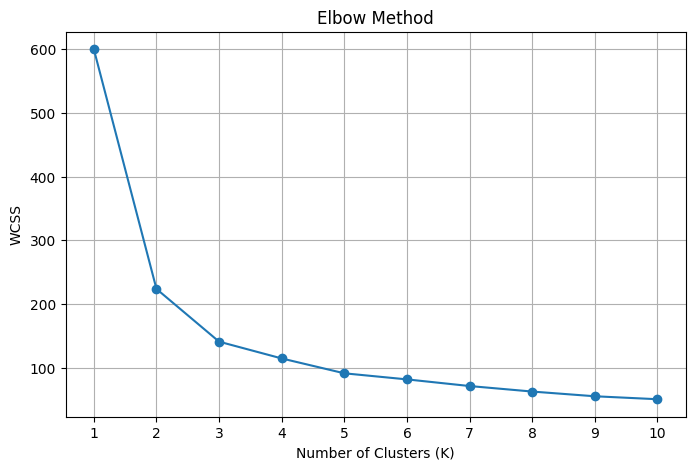

In [4]:
wcss = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, init="k-means++", random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

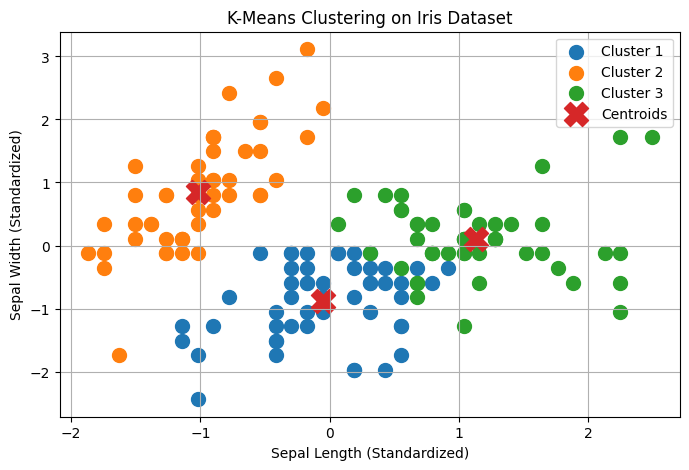

Cluster Centroids:
[[-0.05021989 -0.88029181  0.34753171  0.28206327]
 [-1.01457897  0.84230679 -1.30487835 -1.25512862]
 [ 1.13597027  0.09659843  0.996271    1.01717187]]

Number of points in each cluster:
0    53
1    50
2    47
Name: count, dtype: int64


In [5]:
kmeans = KMeans(n_clusters=3, init="k-means++", random_state=42, n_init=10)
y_kmeans = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 5))
for cluster in range(3):
    plt.scatter(
        X_scaled[y_kmeans == cluster, 0],
        X_scaled[y_kmeans == cluster, 1],
        s=100, label=f"Cluster {cluster + 1}"
    )

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=300, marker="X", label="Centroids"
)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Sepal Length (Standardized)")
plt.ylabel("Sepal Width (Standardized)")
plt.legend()
plt.grid(True)
plt.show()

print("Cluster Centroids:")
print(kmeans.cluster_centers_)
print("\nNumber of points in each cluster:")
print(pd.Series(y_kmeans).value_counts().sort_index())

In [ ]:
# ========== ML PRACTICAL 4: K-MEANS CLUSTERING ==========

# AIM: Group Iris flowers using K-Means and find optimal K.
# FLOW: Load -> Inspect -> Scale -> Cluster -> Elbow -> Visualize

# THEORY:
# Clustering = grouping similar data points together.
# K-Means = unsupervised learning algorithm.
# K = number of clusters; Centroid = center of a cluster.
# K-Means groups points based on distance from centroids.
# Elbow Method = finds suitable K using WCSS graph.
# WCSS = Within-Cluster Sum of Squares (lower = tighter clusters).
# Elbow point = where WCSS reduction starts slowing down.
# K-Means++ = smart centroid initialization.

# LIBRARIES:
# pandas(pd) = dataset handling; numpy(np) = numerical operations.
# matplotlib(plt) = graphs; StandardScaler = feature scaling.
# KMeans = clustering algorithm from sklearn.

# DATA LOADING:
# pd.read_csv(url) = loads Iris CSV dataset.
# head() = first 5 rows; info() = column types and counts.
# describe() = statistics (mean, std, min, max, quartiles).
# isnull().sum() = counts missing values.
# X = 4 features: sepal length/width, petal length/width.

# SCALING:
# StandardScaler() = standardizes data (mean 0, std 1).
# fit_transform(X) = learns scaling + transforms features.
# WHY? Prevent large-scale features dominating distances.

# K-MEANS:
# KMeans(n_clusters=3,init="k-means++",random_state=42,n_init=10)
# n_clusters=3 = creates 3 clusters.
# init="k-means++" = chooses smart starting centroids.
# random_state=42 = reproducible results.
# n_init=10 = runs K-Means 10 times, keeps best result.
# fit_predict(X_scaled) = trains model + assigns cluster labels.
# y_kmeans = predicted cluster labels (0, 1, 2).
# fit(X_scaled) = trains clustering model.
# cluster_centers_ = final centroid coordinates.

# ELBOW METHOD:
# wcss=[] = empty list to store WCSS values.
# range(1,11) = tries K from 1 to 10.
# inertia_ = WCSS (sum of squared distances to centroids).
# append() = adds each WCSS value to list.
# plot(range(1,11),wcss,marker="o") = draws elbow graph.
# marker="o" = circular points.
# xlabel()/ylabel() = axis labels; title() = graph title.
# xticks() = X-axis tick positions; grid(True) = shows grid.
# show() = displays graph.

# CLUSTER VISUALIZATION:
# for cluster in range(3) = loops through 3 clusters.
# y_kmeans == cluster = selects points belonging to cluster.
# X_scaled[mask,0] = standardized sepal length.
# X_scaled[mask,1] = standardized sepal width.
# scatter(x,y,s=100,label=...) = plots cluster points.
# s=100 = marker size; label = legend name.
# cluster_centers_[:,0] = centroid sepal length.
# cluster_centers_[:,1] = centroid sepal width.
# s=300,marker="X" = large X-shaped centroid markers.
# legend() = displays cluster labels.

# RESULTS:
# print(cluster_centers_) = displays 4D centroid coordinates.
# pd.Series(y_kmeans) = converts cluster labels to a Series.
# value_counts() = number of points in each cluster.
# sort_index() = sorts results by cluster number.
# NOTE: Graph shows only 2 features, but K-Means uses all 4.
# NOTE: K=3 is preset; Elbow graph helps check if suitable.

# ========== 4 IMPORTANT VIVA QUESTIONS ==========

# Q1. What is clustering?
# Ans: Unsupervised learning that groups similar data points.

# Q2. Where is clustering used in real life?
# Ans: Customer segmentation, image segmentation,
#      recommendation systems and fraud pattern analysis.

# Q3. When to use K-Means vs K-Medians?
# Ans: K-Means uses mean centroids and squared Euclidean distance;
#      suitable for compact clusters without strong outliers.
#      K-Medians uses median centers and usually Manhattan distance;
#      more resistant to outliers.

# Q4. Classification vs Clustering?
# Ans: Classification = supervised, uses labeled data.
#      Clustering = unsupervised, discovers groups without labels.

# FINAL VIVA EXPLANATION:
# "We load the Iris dataset with four flower features,
# standardize them, apply K-Means to form 3 clusters,
# use the Elbow Method to study suitable K using WCSS,
# visualize clusters and centroids, and display cluster counts."